[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SURIAPRAKASH1/reinforcement_learning/blob/main/notebooks/approximation-methods.ipynb)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import numpy as np
import math
import matplotlib.pyplot as plt
import random
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
import itertools
from queue import deque

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Currently available device -->", DEVICE)

Currently available device --> cpu


# Value-Function Approximation:
- Approximation methods approximates the value-function table with fewer parameters.
- It's called function-approximation cuase we use functions like linear or neural networks to generalize value-function.

## State-Value Function approximation:
- For any arbitrary fixed policy we learn state-value function $v_{\pi}(s)$ as table, instead of leaning table we use $\hat{v}(S, \textbf{w})$ to approximate.
- By nudgeing weight parameters $\textbf{w}$, learn state-value function distripution that generalize to true $v_{\pi}(s)$.


### Gradient Monte Carlo Algorithm for estimating $\hat{v} \approx v_{\pi}$

In [ ]:
gamma = 1.0
alpha = 0.01
Episodes = 1

# Feature construction - Polynomial Basis
n, k = 3, 2       # n => n-order (hyper-parameter) , k => dim or components of raw state
exponents =  torch.tensor(list(itertools.product(range(n + 1), repeat = k)))
# states/feature are stacked as column in matrix
POLY_FEA = lambda s: torch.as_tensor(s, device = DEVICE).pow(exponents).prod(dim = -1).view(1, -1)

# Value-Function weight
w = torch.randn(size = (exponents.size(0), 1), device = DEVICE)          # Weights (neuron if NN) are stacked as row in matrix

# Store Value estimate finally
estimated_values = []

for ep in range(Episodes):

    state, info = env.reset()
    states = [state]
    rewards = []
    while True:
        # Let's consider fixed policy: gives 0.5 probs for a = 1, 2
        if random.random() >= 0.5:
            action = 1
        else:
            action = 2

        # Take action A and observe R, S'
        next_state, reward, terminated, truncated, _ = env.step(action)
        rewards.append(reward)
        if terminated or truncated:
            break
        states.append(next_state)

    T = len(rewards)
    discounts = gamma ** np.arange(T)
    # With Monte Carlo return is always unbaised but have high variance
    G = torch.tensor(np.cumsum(rewards[::-1] * discounts[::-1])[::-1] / discounts, device = DEVICE, dtype = torch.float32)

    for t, s in enumerate(states):
        # Approximated value for state
        x_s = POLY_FEA(s)
        v_hat = x_s @ w
        # Objective is Mean-Square Error with SGD weight update comes to simple as,
        w += alpha * ((G[t] - v_hat) * x_s).transpose(1, 0)

    if ep == Episodes - 1:
        for s in states:
            v_hat = POLY_FEA(s) @ w
            estimated_values.append(v_hat.item())

## Action-Value Functoin Approximation:
### Episodic Semi-Gradient $Sarsa$ for estimating $\hat{q} \approx q_{*} $:
- Sarsa used for control problems: Semi-Gradient means using stochastic gradient descent to update weights of function approximator, it called semi-gradient cause gradient only depends on approximated $\hat{q}$ value only not on target.
  
   $\hspace{5em} \hat{q}(S, A, \textbf{w}) \approx q_{\pi}(S, A)$.
- Target for Sarsa: $R_{t+1} + \gamma \hat{q}(S', A', \textbf{w})$ and the update with SGD with linear methods ,
  
$\hspace{5em} \textbf{w}_{t+1} \leftarrow \textbf{w}_t + \alpha [R_{t+1} + \gamma \hat{q}(S', A', \textbf{w}) - \hat{q}(S_t, A_t, \textbf{w}) ] \hat{q}(S_t, A_t, \textbf{w})$
- Because of Sarsa it's on-policy (cause if off-policy it will be SarsaMax (Q-learning))
  

In [ ]:
# Linear Method for Approximating q
class QHat(nn.Module):

    def __init__(self, in_features: int, out_features: int = 1):
        super().__init__()

        self.l1 = nn.Linear(in_features, out_features, bias= False)

        # Initial Values of weights: Here fill with 0.0 cause that's what sutton did
        torch.nn.init.zeros_(self.l1.weight)

    def forward(self, x) -> torch.Tensor:
        return self.l1(x)

# WE are using polinomial feature bais but sutton used tile coding with 8-tilling
n, k = 8, 2       # n => n-order (hyper-parameter) , k => dim or components of raw state
exponents =  torch.tensor(list(itertools.product(range(n + 1), repeat = k)))
# states/feature are stacked as column in matrix
POLY_FEA = lambda s: torch.as_tensor(s, device = DEVICE).pow(exponents).prod(dim = -1).view(1, -1)
def build_feature(s, a = None):
    if not isinstance(a, int):
        return torch.cat([POLY_FEA(s).repeat_interleave(3, torch.tensor(0)),
                                torch.tensor([[-1], [0], [1]], dtype =torch.float32, device = DEVICE)], dim = -1)
    else:
        return torch.cat([POLY_FEA(state),
                          torch.tensor([[a - 1]], dtype = torch.float32, device = DEVICE)], dim = -1)

def epsilon_greedy_policy(qhat, state):
    "On-policy uses epsilon policy (instance of soft-policy) to select action"

    if random.random() >= epsilon: # Greedy
        action = qhat(build_feature(state)).argmax(dim = 0).item()
    else: # epsilon-greedy
        action = torch.softmax(qhat(build_feature(state)).flatten(), dim = 0).multinomial(1).item()
    return action

def return_values(qhat, env):
    "With trained qhat predict values for (s,a) pair for single episode"

    qhat.eval()
    values = []
    state, _ = env.reset()
    while True:
        val, action = qhat(build_feature(state)).max(dim = 0)
        values.append(-val.item())
        state, _, terminated, truncated, _ = env.step(action.item())
        if terminated or truncated:
            break
    return values

In [ ]:
# Algorithm hyperparameters:
gamma = 1.0                  # Discount Factor: 1.0 cause it's episodic task, won't need to consider
Episodes = 100               # Total number of episodes we want to train
alpha = 0.006 # 0.5 / 82             # Step size
epsilon = 0.1                # Exploration Rate

# Initiate action-value function approximator
qhat = QHat( (n + 1) ** 2 + 1, 1 ).to(DEVICE)

# Mean Square Error objective
loss_fn =  torch.nn.MSELoss()
# Stochastic Gradient Descent
qhat_optimizer = torch.optim.SGD(qhat.parameters(), lr = alpha)
# lr_decay = torch.optim.lr_scheduler.ExponentialLR(qhat_optimizer, 0.00001)

#------------------------------
# Optimaization Loop/ Training
# -----------------------------
for ep in range(Episodes):
    # Sarsa always start's with S, A pair
    state, info = env.reset()
    action = epsilon_greedy_policy(qhat, state)

    losses = 0.0
    episode_len = 0.0
    while True:
        # We don't want to cummulate gradients (may be that would be usefull with gradient_accumulation 🅱)
        qhat_optimizer.zero_grad()

        # Take action A and observe R, S'
        next_state, reward, terminated, truncated, _ =  env.step(action)
        # Approximated action-value
        pred_qhat = qhat(build_feature(state, action))
        # Target: our approximater (qhat) want to predict
        target = torch.as_tensor([[reward]], dtype = torch.float32, device = DEVICE)
        # If terminated, target don't have bootstrapping part
        if terminated or truncated:
            loss = loss_fn(target, pred_qhat)
            # Gradient's Calculation
            loss.backward()
            # Update parameters with Gradients
            qhat_optimizer.step()
            break

        # Choose next action A' function of qhat
        next_action = epsilon_greedy_policy(qhat, next_state)
        # Target = reward + bootstrapping
        target += qhat(build_feature(next_state, next_action)).detach()
        loss = loss_fn(target, pred_qhat)
        # Gradient's Calculation
        loss.backward()
        # Update parameters with Gradients
        qhat_optimizer.step()

        state = next_state
        action = next_action
        # Stacking losses
        losses += loss.item()
        episode_len += 1.0

    # Decay learning rate at end of the each episode
    # lr_decay.step()

    # Following Loss on Episode level
    if ep % 5 == 0 or ep == Episodes - 1:
        print(f"Episode {ep}: Loss = {losses / episode_len}")

## Deep Q-Network/ Deep Q-Learning (DQN/DQL):
- $DQN/DQL$ is an approximation method that uses *$Deep\space Neural\space Network$* to approximate $action-value\space function$.
- DQN is also *off-policy* method that means it has *target* and *behaviour* policy.
- By acting greedy with respect to learned action-value function, an agent selects an optimal action on each state.
- The special features of DQN is unlike any RL online (step-by-step) learning that is very unstable to train neural networks, DQN uses $Experience-Replay$ and $supervised-learning$ with $stochastic$ $mini-batch$.

In [ ]:
# Let's train and Agent with the famous mountain car environment
mountaincar_env = gym.make("MountainCar-v0")

# Dim of the state
k = mountaincar_env.observation_space.shape[0]
# Action Space: Total number of actions
action_space = mountaincar_env.action_space.n.item()

# ---------------
# HyperParameters
# ---------------
n = 3                                # Order-n Fourier cosine basis -> feature construction
max_experience_replay_size = 10000   # Max Experience replay size
# Expolration schemes
EPS_START = 0.9
EPS_END = 0.01
EPS_DECAY = 2500
GAMMA = 0.99                         # Discount factor
alpha = 3e-4                         # Step size (compare to SL, RL step size have more intuitive info)
Episodes = 500                       # How many episodes we want to train our an Agent ?
batch_size = 128                     # Sample dataset size
target_update_episodes = 25          # How often one want to update traget network during traning ?
tau = 0.005                          # Soft-update for target network

In [ ]:
# Deep Neural Network for approximating action-value function
class QLearning(nn.Module):

    def __init__(self, in_features:int, hidden_dim1:int, hidden_dim2:int, out_features:int) -> None:
        """
        Dense NN with one hidden layer.

        Args:
            in_features : Dimentionality of state feature
            hidden_dim1 : Input Dimentionality of hidden layer
            hidden_dim2 : Output Dimentionality of hidden hidden layer
            out_features : Action space size
        """
        super().__init__()
        self.l1 = nn.Sequential(
            nn.Linear(in_features, hidden_dim1),
            nn.RMSNorm(hidden_dim1, eps=1e-8),
            nn.GELU()
        )

        self.l2 = nn.Sequential(
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.RMSNorm(hidden_dim2, eps=1e-8),
            nn.GELU()
        )

        self.l3 = nn.Linear(hidden_dim2, out_features)

    def get_device(self):
        return next(self.parameters()).device.type

    def _get_parameters(self):
        total = 0.0
        for p in self.parameters():
            total += p.nelement()
        return total

    def forward(self, x) -> torch.Tensor:
        return self.l3(self.l2(self.l1(x)))

def soft_update(target_net: nn.Module, q_learning_net: nn.Module, tau: float):
    "Soft update to target network parameters. Gradually changing instead hard."
    for target_params, q_learning_params in zip(target_net.parameters(), q_learning_net.parameters()):
        target_params.data.copy_((1 - tau) * target_params.data + tau * q_learning_params.data)

steps_done = 0.0
def epsilon_greedy_policy(state, policy: nn.Module, d):
    "Behaviour Policy -> epsilon-greedy: Used to generate data"
    global steps_done
    eps_threshold = EPS_END + (EPS_START - EPS_END) * \
        math.exp(-1. * steps_done / EPS_DECAY)
    steps_done += 1.0
    if np.random.random() < eps_threshold:    # Exploration
        action = mountaincar_env.action_space.sample().item()
    else:                                     # Exploitation
        state_fea = d.generate_fourier_features(state).to(policy.get_device())
        with torch.no_grad():
            action = policy(state_fea.unsqueeze(0)).argmax(dim = -1).item()
    return action

class ExperienceReplay(Dataset):

    def __init__(self, max_experience_replay_size: int, k: int, order_n: int):
        self.memory = deque(maxlen = max_experience_replay_size)
        # ---------------------
        # Fearture Construction
        # ---------------------

        # Boundary for postion and velocity: Defined as how in gym lib
        self.min_pos_vel = np.array([-1.2, -0.07], dtype = np.float32)
        self.max_pos_vel = np.array([0.6, 0.07], dtype = np.float32)

        # Generate all coefficient vectors (c_i) => range of integers for each component of c_i: {0, 1, ..., n}
        self.all_c_vectors = list(itertools.product(range(0, order_n + 1), repeat=k))

    def __len__(self):
        return len(self.memory)

    def update(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def generate_fourier_features(self, s: np.ndarray) -> torch.tensor:
        """Constructs the n-order Fourier cosine basis feature vector x(s).

        Args:
            s: state vector (must be 1D).
            order_n: The maximum integer magnitude for the coefficients c_i,j.
        Returns:
            A tensor representing the full feature vector x(s), of size (order_n + 1)^k.
        """
        # 1. Input Validation and Setup
        state_vector = np.asarray(s, dtype=float)

        # 2. Scalling state to within range of [0, 1]
        state_vector = (state_vector - self.min_pos_vel) / (self.max_pos_vel - self.min_pos_vel)

        # 3. Calculate the feature vector x(s)
        feature_list = []

        for c_tuple in self.all_c_vectors:
            c_i = np.array(c_tuple)

            # Calculate the inner product: s^T * c_i
            # (This combines the scaled state dimensions and the frequencies)
            s_dot_c = np.dot(state_vector, c_i)

            # Calculate the feature: cos(pi * s^T * c_i)
            feature_value = np.cos(np.pi * s_dot_c)
            feature_list.append(feature_value)

        return torch.as_tensor(feature_list, dtype = torch.float32)

    def __getitem__(self, idx):
        state, action, reward, next_state, done = self.memory[idx]
        state_fea = self.generate_fourier_features(state)
        next_state_fea = self.generate_fourier_features(next_state)
        return (state_fea,
                torch.tensor(action),
                torch.tensor(reward, dtype = torch.float32),
                next_state_fea, torch.tensor(done, dtype = torch.bool))

class Trainer:

    def __init__(self, alpha: float = 0.001, weight_decay: float = 0.1, batch_size: int = 32):

        self.alpha = alpha
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.q_optimizer = None
        self.mountaincar_dataloader = None

    def train(self, q_learning_network: nn.Module, target_network: nn.Module,
            mountaincar_dataset, batches:int = 1, gamma = 1.0):
        "When experience replay is got enought sample we are doing Supervised Learning."

        if len(mountaincar_dataset) < batch_size:
            return

        if self.mountaincar_dataloader is None:
            self.mountaincar_dataloader = DataLoader(mountaincar_dataset, self.batch_size, shuffle= True,
                                                pin_memory= True if DEVICE == 'cuda' else False)

        losses = 0.0
        # Usually single batch is enough. If we multiple batch then agen will overfit
        for batch, (states, actions, rewards, next_states, dones) in enumerate(self.mountaincar_dataloader):
            if DEVICE == 'cuda':
                states, next_states = states.to(DEVICE), next_states.to(DEVICE)
                rewards, dones = rewards.to(DEVICE), dones.to(DEVICE)

            if self.q_optimizer is None:
                self.q_optimizer = optim.AdamW(q_learning_network.parameters(),
                                              lr = alpha, weight_decay= self.weight_decay)
            self.q_optimizer.zero_grad()

            # Forward pass: Feed function approximator (NN) with states to approximate q values
            q_values = q_learning_network(states)              #  (B -> batch_size, AS -> Action space)

            # Compute q_hat(S, A) and max_a' q_hat(S', a') at batch level
            pred = q_values[torch.arange(0, q_values.shape[0]), actions]
            with torch.no_grad():
                next_q_values = target_network(next_states)
                target = rewards + gamma * next_q_values.max(dim = 1).values * ~ dones
            # Compute loss
            loss = F.smooth_l1_loss(pred, target)
            # Backward pass: Compute gradients
            loss.backward()
            # In palce gradient clipping
            nn.utils.clip_grad_norm_(q_learning_network.parameters(), 0.3)
            # Update Parameters
            self.q_optimizer.step()

            losses = loss.item()
            if batch == batches - 1:
                break
        return losses

In [ ]:
# Initiate Deep Networks: ~ 7k parameters, ~ >=100 episodes is enought to get agent
q_learning_network = QLearning((n + 1 )**k, 100, 50, action_space).to(DEVICE)
target_network = QLearning((n + 1)**k, 100, 50, action_space).to(DEVICE)

# Copy parameters of learning net to target net
target_network.load_state_dict(state_dict= q_learning_network.state_dict())

# Initiate Dataset
mountaincar_dataset = ExperienceReplay(max_experience_replay_size, k, n)

# Initiate Trainer
trainer = Trainer(alpha= alpha, weight_decay= 1e-4, batch_size= batch_size)

In [ ]:
losses = []

# Every 2000 run's show loss as average
runs = 0.0
runs_loss = 0.0

# Optimization / Training Loop
for ep in range(Episodes):
    # Each episode start's as a new
    state, _ = mountaincar_env.reset()
    while True:
        # Observer S and Take A according to policy
        action = epsilon_greedy_policy(state, q_learning_network, mountaincar_dataset)
        # Observer R, S'
        next_state, reward, done, truncated, _ = mountaincar_env.step(action)
        # Store agent's tragectory (S, A, R, S')
        mountaincar_dataset.update(state, action, reward, next_state, done)
        state = next_state

        # Train Agent in Supervised manner
        loss = trainer.train(q_learning_network, target_network, mountaincar_dataset, gamma= GAMMA)

        # Update (soft-update) Target network at every time step
        soft_update(target_network, q_learning_network, tau)

        if loss:
            losses.append(loss)
            runs += 1.0
            runs_loss += loss
            if runs == 2000.0:
                print(f"Episode {ep} | Runs: {runs}: loss = {runs_loss / runs}")
                runs, runs_loss = 0.0, 0.0

        if done or truncated:
            break


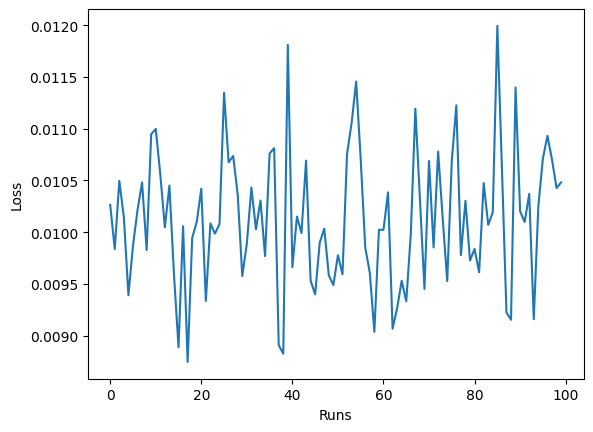

In [ ]:
plt.plot(torch.tensor(losses)[:-17].view(-1, 100).mean(dim = 0))
plt.xlabel("Runs")
plt.ylabel("Loss")
plt.show()

### Evaluate DQN

In [ ]:
import glob
from IPython.display import display, Video

In [ ]:
q_learning_network.eval()
env = gym.make("MountainCar-v0", render_mode="rgb_array")
env = RecordVideo(env, video_folder="/content/videos", episode_trigger=lambda x: True)  # record all episodes

rewards = 0.0
state = env.reset()[0]
done = False
while not done:
    action = q_learning_network(mountaincar_dataset.generate_fourier_features(state).to(DEVICE)).argmax(dim=0).item()
    state, reward, done, truncated, _ = env.step(action)
    rewards += reward

env.close()

# find the mp4 in /content/videos and display it (first video)
videos = sorted(glob.glob("/content/videos/*.mp4"))
print("Saved videos:", videos)
print(f"Time step takes for agent to complete: {-rewards}")


In [ ]:
display(Video(videos[-1], embed=True, width=640, height=480))